Step 1: Environment Setup & Data Loading
Run this first cell to establish connection to the warehouse built in Phase 1. (mgas_warehouse.db)

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Connect to Phase 1 Warehouse
DB_PATH = '../data/mgas_warehouse.db'
SCENARIO_DATE = '2026-08-06'

conn = sqlite3.connect(DB_PATH)

# Load Core Tables
customers = pd.read_sql("SELECT * FROM Dim_Customer", conn)
transactions = pd.read_sql("SELECT * FROM Fact_Transactions WHERE status='Success'", conn)
agents = pd.read_sql("SELECT * FROM Dim_Agent", conn)
telemetry = pd.read_sql("SELECT * FROM Fact_IoT_Telemetry", conn)

# Parse Dates
transactions['transaction_date'] = pd.to_datetime(transactions['transaction_date'])
customers['signup_date'] = pd.to_datetime(customers['signup_date'])

print(f"✅ Loaded {len(customers)} customers, {len(transactions)} transactions")

✅ Loaded 1000 customers, 4197 transactions


Step 2: Cohort Retention Analysis (The Triangular Heatmap)
This visualizes the "Leaky Bucket." We track customers by their signup month and see what % are still active in subsequent months.

Connected database location: C:\Data\commercial-data-analyst-job-m-gas\data\mgas_warehouse.db
Customers loaded: 1,000
Transactions loaded: 4,546
M0 validation passed: Every signup cohort has 100% retention.

DATA QUALITY SUMMARY
--------------------
Total customers: 1,000
Total transaction records: 4,546
Successful transactions: 4,197
Signup cohorts: 7
Scenario anchor: 2026-08-06
Last complete month: 2026-07


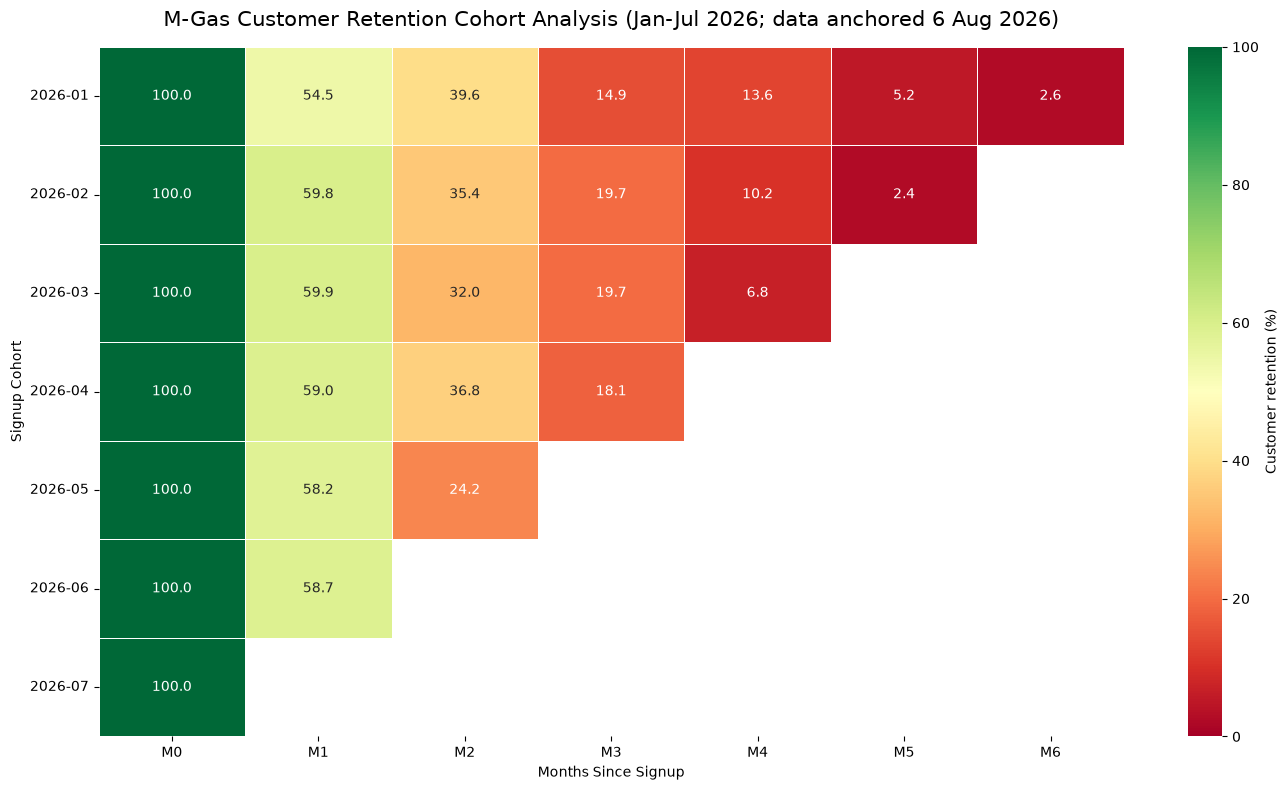


COHORT INSIGHT
--------------
Average Month-2 Retention: 33.6%
Based on 5 fully observed signup cohorts.
CRITICAL: M2 retention is below 70%. Investigate onboarding effectiveness, refill frequency, affordability, service reliability and customer engagement.


In [2]:
# ============================================================
# STEP 2: COHORT RETENTION ANALYSIS
# M-Gas | Scenario anchor: 2026-08-06
# ============================================================

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 1. LOAD FRESH DATA FROM SQLITE
# ============================================================


from pathlib import Path

# Absolute path to the M-Gas project database
PROJECT_ROOT = Path(
    r"C:\Data\commercial-data-analyst-job-m-gas"
)

DB_NAME = PROJECT_ROOT / "data" / "mgas_warehouse.db"

SCENARIO_ANCHOR = pd.Timestamp(
    "2026-08-06 23:59:59"
)

# Confirm that the database actually exists.
if not DB_NAME.is_file():
    raise FileNotFoundError(
        f"M-Gas database not found: {DB_NAME}\n"
        f"Current Jupyter working directory: {Path.cwd()}\n"
        "Run src/generate_data.py from the project root first."
    )

print(f"Connected database location: {DB_NAME}")

with sqlite3.connect(str(DB_NAME)) as conn:

    customers = pd.read_sql_query(
        """
        SELECT customer_id, signup_date, segment
        FROM Dim_Customer
        """,
        conn
    )

    transactions = pd.read_sql_query(
        """
        SELECT
            transaction_id,
            customer_id,
            transaction_date,
            amount_kes,
            payment_method,
            status
        FROM Fact_Transactions
        """,
        conn
    )

print(f"Customers loaded: {len(customers):,}")
print(f"Transactions loaded: {len(transactions):,}")


# ============================================================
# 2. NORMALIZE DATES
# ============================================================

customers["signup_date"] = pd.to_datetime(
    customers["signup_date"],
    errors="coerce"
)

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

customers = customers.loc[
    customers["signup_date"].notna()
    & customers["signup_date"].le(SCENARIO_ANCHOR)
].copy()

transactions = transactions.loc[
    transactions["transaction_date"].notna()
    & transactions["transaction_date"].le(SCENARIO_ANCHOR)
].copy()


# Validate customer uniqueness.

if customers["customer_id"].duplicated().any():

    raise ValueError(
        "Duplicate customer IDs found in Dim_Customer."
    )


# ============================================================
# 3. DEFINE SIGNUP COHORTS
# ============================================================

customers["cohort_period"] = (
    customers["signup_date"].dt.to_period("M")
)

# Ground-truth cohort sizes from Dim_Customer.

cohort_sizes = (
    customers.groupby("cohort_period")["customer_id"]
    .nunique()
    .sort_index()
)


# ============================================================
# 4. FILTER SUCCESSFUL TRANSACTIONS
# ============================================================

successful = transactions.loc[
    transactions["status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("success")
].copy()


# ============================================================
# 5. JOIN TRANSACTIONS TO CUSTOMER COHORTS
# ============================================================

activity = successful.merge(
    customers[
        [
            "customer_id",
            "signup_date",
            "cohort_period"
        ]
    ],
    on="customer_id",
    how="inner",
    validate="many_to_one"
)

# Remove any activity before signup.

activity = activity.loc[
    activity["transaction_date"].ge(
        activity["signup_date"]
    )
].copy()


# ============================================================
# 6. CALCULATE MONTHS SINCE SIGNUP
# ============================================================

activity["activity_period"] = (
    activity["transaction_date"].dt.to_period("M")
)

# Vectorized calendar-month calculation.
# No row-by-row apply().

activity["months_since_signup"] = (

    (
        activity["activity_period"].dt.year
        - activity["cohort_period"].dt.year
    ) * 12

    +

    activity["activity_period"].dt.month
    - activity["cohort_period"].dt.month

).astype("int64")


if activity["months_since_signup"].lt(0).any():

    raise ValueError(
        "Negative months_since_signup detected."
    )


# ============================================================
# 7. COUNT UNIQUE ACTIVE CUSTOMERS
# ============================================================

cohort_counts = (

    activity.groupby(
        [
            "cohort_period",
            "months_since_signup"
        ]
    )["customer_id"]

    .nunique()

    .unstack("months_since_signup")
)

# Preserve every cohort from Dim_Customer.
# Missing cohort/month combinations mean zero observed activity.

cohort_counts = (
    cohort_counts
    .reindex(index=cohort_sizes.index)
    .fillna(0)
)


# ============================================================
# 8. DETERMINE FULLY OBSERVED MONTHS
# ============================================================

# The scenario anchor is 6 August 2026.
# July 2026 is the last fully completed calendar month.

last_complete_period = (
    SCENARIO_ANCHOR.to_period("M") - 1
)

max_age_by_cohort = pd.Series(

    [
        (
            (last_complete_period.year - cohort.year) * 12
            +
            last_complete_period.month - cohort.month
        )

        for cohort in cohort_sizes.index
    ],

    index=cohort_sizes.index,

    dtype="int64"
)

max_age = (
    int(max_age_by_cohort.max())
    if not max_age_by_cohort.empty
    else 0
)

age_columns = list(range(max_age + 1))

cohort_counts = cohort_counts.reindex(
    columns=age_columns,
    fill_value=0
)


# ============================================================
# 9. CALCULATE CUSTOMER RETENTION
# ============================================================

# Retention =
# Unique active customers / Original cohort size * 100

# Denominator always comes from Dim_Customer.

retention = (

    cohort_counts
    .div(cohort_sizes, axis="index")
    .mul(100)

)


# Mask incomplete/future lifecycle months.

observation_mask = pd.DataFrame(

    {
        age: max_age_by_cohort.ge(age)
        for age in age_columns
    },

    index=cohort_sizes.index
)

retention = retention.where(
    observation_mask
)


# ============================================================
# 10. VALIDATE M0 = 100%
# ============================================================

m0_counts = cohort_counts[0]

m0_pct = (
    m0_counts
    .div(cohort_sizes)
    .mul(100)
)

if not np.isclose(
    m0_pct.to_numpy(dtype=float),
    100.0,
    atol=1e-9
).all():

    failed_cohorts = m0_pct[
        ~np.isclose(
            m0_pct.to_numpy(dtype=float),
            100.0,
            atol=1e-9
        )
    ].round(2).to_dict()

    raise ValueError(
        "M0 validation failed. "
        f"Problem cohorts: {failed_cohorts}"
    )


print(
    "M0 validation passed: "
    "Every signup cohort has 100% retention."
)


# ============================================================
# 11. DATA QUALITY SUMMARY
# ============================================================

print("\nDATA QUALITY SUMMARY")
print("--------------------")

print(
    f"Total customers: "
    f"{customers['customer_id'].nunique():,}"
)

print(
    f"Total transaction records: "
    f"{len(transactions):,}"
)

print(
    f"Successful transactions: "
    f"{len(successful):,}"
)

print(
    f"Signup cohorts: "
    f"{len(cohort_sizes):,}"
)

print(
    f"Scenario anchor: "
    f"{SCENARIO_ANCHOR:%Y-%m-%d}"
)

print(
    f"Last complete month: "
    f"{last_complete_period}"
)


# ============================================================
# 12. PLOT COHORT RETENTION HEATMAP
# ============================================================

plt.figure(figsize=(14, 8))

sns.heatmap(

    retention,

    annot=True,

    fmt=".1f",

    cmap="RdYlGn",

    vmin=0,

    vmax=100,

    mask=retention.isna(),

    linewidths=0.5,

    linecolor="white",

    cbar_kws={
        "label": "Customer retention (%)"
    }

)

plt.title(

    "M-Gas Customer Retention Cohort Analysis "
    "(Jan-Jul 2026; data anchored 6 Aug 2026)",

    fontsize=15,

    pad=15

)

plt.xlabel("Months Since Signup")

plt.ylabel("Signup Cohort")

plt.xticks(

    ticks=np.arange(len(age_columns)) + 0.5,

    labels=[
        f"M{i}" for i in age_columns
    ],

    rotation=0

)

plt.yticks(

    ticks=np.arange(len(retention.index)) + 0.5,

    labels=[
        str(period) for period in retention.index
    ],

    rotation=0

)

plt.tight_layout()

plt.show()


# ============================================================
# 13. COMMERCIAL BUSINESS INSIGHT: M2 RETENTION
# ============================================================

print("\nCOHORT INSIGHT")
print("--------------")

if 2 not in retention.columns:

    print(
        "M2 retention cannot be calculated: "
        "no fully observed M2 cohort is available."
    )

else:

    # Only include cohorts with a fully observed M2.

    eligible_m2 = retention.loc[
        max_age_by_cohort.ge(2),
        2
    ].dropna()

    if eligible_m2.empty:

        print(
            "M2 retention cannot be calculated: "
            "no fully observed M2 cohort is available."
        )

    else:

        avg_m2 = eligible_m2.mean()

        print(
            f"Average Month-2 Retention: "
            f"{avg_m2:.1f}%"
        )

        print(
            f"Based on {len(eligible_m2)} "
            "fully observed signup cohorts."
        )

        if avg_m2 < 70:

            print(
                "CRITICAL: M2 retention is below 70%. "
                "Investigate onboarding effectiveness, "
                "refill frequency, affordability, service "
                "reliability and customer engagement."
            )

        elif avg_m2 > 90:

            print(
                "EXCELLENT: M2 retention is above 90%. "
                "Customers demonstrate strong early "
                "lifecycle engagement."
            )

        else:

            print(
                "MODERATE: Investigate the main drivers "
                "of customer drop-off between signup and M2."
            )

Business question: Are some agents generating high customer acquisition volumes but failing to generate repeat business?
This version calculates activity per unique customer, not per transaction.


AGENT PERFORMANCE SUMMARY
               name       region  assigned_customers  activated_customers  active_customers_30d  retention_30d_pct  inactivity_30d_pct  revenue_kes
    Rev Kyalo Khisa       Kiambu                  58                   58                    10              17.24               82.76     232500.0
     Benson Mohamed       Kiambu                  52                   52                    11              21.15               78.85     275000.0
     Winfred Mwangi Nairobi West                  49                   49                    12              24.49               75.51     253500.0
        Anna Otieno Nairobi East                  48                   48                    12              25.00               75.00     234000.0
    Caroline Kanini Nairobi East                  43                   43                    11              25.58               74.42     223500.0
       Julius Mutai Nairobi East                  42                   42            

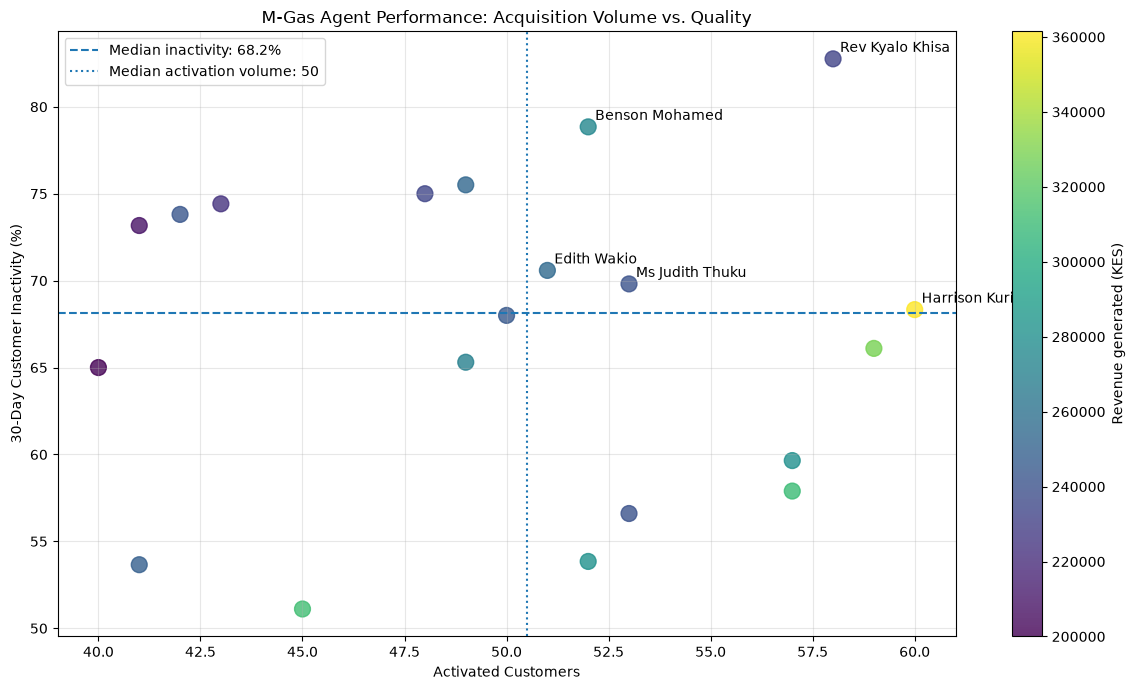


AGENT PERFORMANCE INSIGHT
Highest inactivity: Rev Kyalo Khisa (82.8%)
Lowest inactivity: Mercy Kamau (51.1%)

RECOMMENDATION:
Investigate agent onboarding quality, customer follow-up and repeat-purchase performance.
Consider measuring agent compensation against 30-day retained activations, not just initial signups.


In [3]:
# ============================================================
# STEP 3: AGENT PERFORMANCE VS. QUALITY MATRIX
# M-Gas | Scenario anchor: 2026-08-06
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sqlite3


# ============================================================
# 1. LOAD DATA
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Data\commercial-data-analyst-job-m-gas"
)

DB_NAME = PROJECT_ROOT / "data" / "mgas_warehouse.db"

SCENARIO_DATE = pd.Timestamp("2026-08-06 23:59:59")

with sqlite3.connect(str(DB_NAME)) as conn:

    customers = pd.read_sql_query(
        "SELECT customer_id, agent_id, signup_date "
        "FROM Dim_Customer",
        conn
    )

    agents = pd.read_sql_query(
        "SELECT agent_id, name, region "
        "FROM Dim_Agent",
        conn
    )

    transactions = pd.read_sql_query(
        """
        SELECT
            transaction_id,
            customer_id,
            transaction_date,
            amount_kes,
            status
        FROM Fact_Transactions
        """,
        conn
    )


# ============================================================
# 2. NORMALIZE AND FILTER DATA
# ============================================================

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

successful = transactions.loc[
    transactions["status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("success")
    & transactions["transaction_date"].notna()
    & transactions["transaction_date"].le(SCENARIO_DATE)
].copy()


# ============================================================
# 3. CALCULATE CUSTOMER-LEVEL PERFORMANCE
# ============================================================

customer_activity = (

    successful.groupby("customer_id")

    .agg(

        successful_transactions=(
            "transaction_id",
            "nunique"
        ),

        customer_revenue=(
            "amount_kes",
            "sum"
        ),

        last_successful_transaction=(
            "transaction_date",
            "max"
        )

    )

    .reset_index()
)


# Every customer must remain in the analysis,
# including customers without successful transactions.

agent_customers = customers.merge(
    customer_activity,
    on="customer_id",
    how="left",
    validate="one_to_one"
)


agent_customers["successful_transactions"] = (
    agent_customers["successful_transactions"]
    .fillna(0)
)

agent_customers["customer_revenue"] = (
    agent_customers["customer_revenue"]
    .fillna(0)
)


# ============================================================
# 4. DEFINE 30-DAY CUSTOMER ACTIVITY
# ============================================================

ACTIVITY_WINDOW_DAYS = 30

activity_cutoff = (
    SCENARIO_DATE
    - pd.Timedelta(days=ACTIVITY_WINDOW_DAYS)
)

agent_customers["is_activated"] = (
    agent_customers["successful_transactions"] > 0
)

agent_customers["is_active_30d"] = (

    agent_customers["last_successful_transaction"]
    .ge(activity_cutoff)

    &

    agent_customers["last_successful_transaction"]
    .le(SCENARIO_DATE)

).fillna(False)


# ============================================================
# 5. AGGREGATE BY AGENT
# ============================================================

agent_summary = (

    agent_customers.merge(
        agents,
        on="agent_id",
        how="left",
        validate="many_to_one"
    )

    .groupby(
        ["agent_id", "name", "region"],
        dropna=False
    )

    .agg(

        assigned_customers=(
            "customer_id",
            "nunique"
        ),

        activated_customers=(
            "is_activated",
            "sum"
        ),

        active_customers_30d=(
            "is_active_30d",
            "sum"
        ),

        successful_transactions=(
            "successful_transactions",
            "sum"
        ),

        revenue_kes=(
            "customer_revenue",
            "sum"
        )

    )

    .reset_index()
)


# ============================================================
# 6. CALCULATE COMMERCIAL KPIs
# ============================================================

agent_summary["activation_rate_pct"] = (

    agent_summary["activated_customers"]

    / agent_summary["assigned_customers"]

    * 100

)

agent_summary["retention_30d_pct"] = (

    agent_summary["active_customers_30d"]

    / agent_summary["activated_customers"]

    .replace(0, np.nan)

    * 100

)

# This is inactivity among previously activated customers.
# It is NOT confirmed contractual or permanent churn.

agent_summary["inactivity_30d_pct"] = (

    100 - agent_summary["retention_30d_pct"]

)

agent_summary["revenue_per_customer_kes"] = (

    agent_summary["revenue_kes"]

    / agent_summary["activated_customers"]

    .replace(0, np.nan)

)


# ============================================================
# 7. DISPLAY AGENT PERFORMANCE TABLE
# ============================================================

agent_summary = agent_summary.sort_values(
    "inactivity_30d_pct",
    ascending=False
)

print("\nAGENT PERFORMANCE SUMMARY")
print("=" * 75)

print(
    agent_summary[
        [
            "name",
            "region",
            "assigned_customers",
            "activated_customers",
            "active_customers_30d",
            "retention_30d_pct",
            "inactivity_30d_pct",
            "revenue_kes"
        ]
    ].round(2).to_string(index=False)
)


# ============================================================
# 8. VISUALIZE VOLUME VS. QUALITY
# ============================================================

plt.figure(figsize=(12, 7))

scatter = plt.scatter(

    agent_summary["activated_customers"],

    agent_summary["inactivity_30d_pct"],

    c=agent_summary["revenue_kes"],

    cmap="viridis",

    s=130,

    alpha=0.8

)

plt.colorbar(
    scatter,
    label="Revenue generated (KES)"
)

median_inactivity = (
    agent_summary["inactivity_30d_pct"].median()
)

plt.axhline(
    median_inactivity,
    linestyle="--",
    label=f"Median inactivity: {median_inactivity:.1f}%"
)

median_volume = (
    agent_summary["activated_customers"].median()
)

plt.axvline(
    median_volume,
    linestyle=":",
    label=f"Median activation volume: {median_volume:.0f}"
)

for _, row in agent_summary.iterrows():

    if (
        row["inactivity_30d_pct"] >= median_inactivity
        and row["activated_customers"] >= median_volume
    ):

        plt.annotate(
            row["name"],
            (
                row["activated_customers"],
                row["inactivity_30d_pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points"
        )


plt.xlabel("Activated Customers")

plt.ylabel("30-Day Customer Inactivity (%)")

plt.title(
    "M-Gas Agent Performance: Acquisition Volume vs. Quality"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 9. COMMERCIAL INSIGHT
# ============================================================

eligible_agents = agent_summary.loc[
    agent_summary["activated_customers"] >= 10
].copy()

print("\nAGENT PERFORMANCE INSIGHT")
print("=" * 45)

if eligible_agents.empty:

    print("Insufficient customer volume for agent comparison.")

else:

    worst_agent = eligible_agents.loc[
        eligible_agents["inactivity_30d_pct"].idxmax()
    ]

    best_agent = eligible_agents.loc[
        eligible_agents["inactivity_30d_pct"].idxmin()
    ]

    print(
        f"Highest inactivity: {worst_agent['name']} "
        f"({worst_agent['inactivity_30d_pct']:.1f}%)"
    )

    print(
        f"Lowest inactivity: {best_agent['name']} "
        f"({best_agent['inactivity_30d_pct']:.1f}%)"
    )

    print(
        "\nRECOMMENDATION:"
        "\nInvestigate agent onboarding quality, "
        "customer follow-up and repeat-purchase performance."
        "\nConsider measuring agent compensation against "
        "30-day retained activations, not just initial signups."
    )

Business question: How many acquired customers progress from their first successful transaction to repeat purchasing?
We need to be honest about the available data.


M-GAS CUSTOMER TRANSACTION FUNNEL
                               Stage  Count  Overall_Conversion_Pct  Previous_Stage_Conversion_Pct  Dropoff_Customers
                Registered Customers   1000                   100.0                         100.00                0.0
        First Successful Transaction   1000                   100.0                         100.00                0.0
       Second Successful Transaction    821                    82.1                          82.10              179.0
        Third Successful Transaction    649                    64.9                          79.05              172.0
Five or More Successful Transactions    411                    41.1                          63.33              238.0


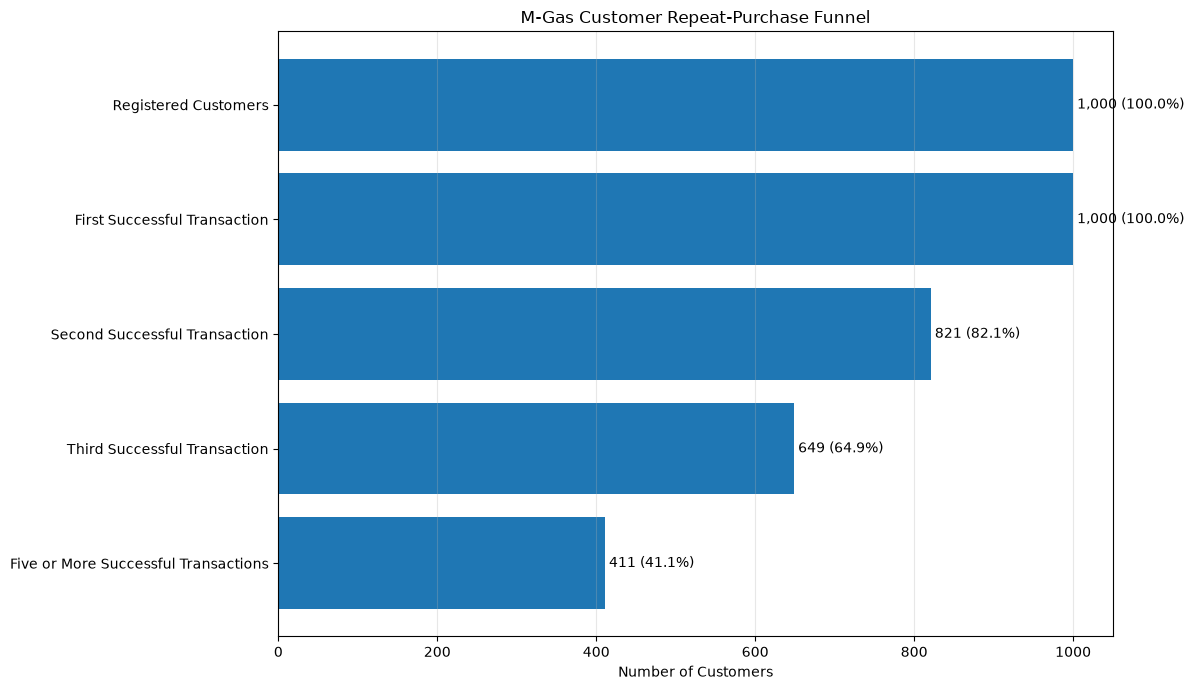


FUNNEL INSIGHT
Largest customer drop-off: 238 customers
At stage: Five or More Successful Transactions
Conversion from previous stage: 63.3%

RECOMMENDATION:
Investigate the customer experience between first purchase and subsequent purchases.
Potential areas include refill convenience, delivery reliability, affordability and customer follow-up.

DATA LIMITATION:
The warehouse does not record separate KYC, deposit, delivery or refill events.
This is a transaction-depth funnel, not a verified operational acquisition funnel.


In [4]:
# ============================================================
# STEP 4: CUSTOMER TRANSACTION FUNNEL
# M-Gas | Scenario anchor: 2026-08-06
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

from pathlib import Path


# ============================================================
# 1. LOAD DATA
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Data\commercial-data-analyst-job-m-gas"
)

DB_NAME = PROJECT_ROOT / "data" / "mgas_warehouse.db"

SCENARIO_DATE = pd.Timestamp("2026-08-06 23:59:59")

with sqlite3.connect(str(DB_NAME)) as conn:

    customers = pd.read_sql_query(
        "SELECT customer_id, signup_date FROM Dim_Customer",
        conn
    )

    transactions = pd.read_sql_query(
        """
        SELECT
            transaction_id,
            customer_id,
            transaction_date,
            amount_kes,
            status
        FROM Fact_Transactions
        """,
        conn
    )


# ============================================================
# 2. FILTER SUCCESSFUL TRANSACTIONS
# ============================================================

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

successful = transactions.loc[

    transactions["status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("success")

    & transactions["transaction_date"].notna()

    & transactions["transaction_date"].le(SCENARIO_DATE)

].copy()


# ============================================================
# 3. CALCULATE SUCCESSFUL TRANSACTIONS PER CUSTOMER
# ============================================================

customer_transactions = (

    successful.groupby("customer_id")

    .agg(

        successful_transaction_count=(
            "transaction_id",
            "nunique"
        ),

        total_revenue_kes=(
            "amount_kes",
            "sum"
        )

    )

    .reset_index()

)


# Preserve all registered customers.

funnel_customers = customers.merge(

    customer_transactions,

    on="customer_id",

    how="left",

    validate="one_to_one"

)

funnel_customers[
    "successful_transaction_count"
] = funnel_customers[
    "successful_transaction_count"
].fillna(0)


# ============================================================
# 4. DEFINE FUNNEL STAGES
# ============================================================

total_registered = len(funnel_customers)

funnel_data = pd.DataFrame({

    "Stage": [

        "Registered Customers",

        "First Successful Transaction",

        "Second Successful Transaction",

        "Third Successful Transaction",

        "Five or More Successful Transactions"

    ],

    "Count": [

        total_registered,

        (
            funnel_customers[
                "successful_transaction_count"
            ] >= 1
        ).sum(),

        (
            funnel_customers[
                "successful_transaction_count"
            ] >= 2
        ).sum(),

        (
            funnel_customers[
                "successful_transaction_count"
            ] >= 3
        ).sum(),

        (
            funnel_customers[
                "successful_transaction_count"
            ] >= 5
        ).sum()

    ]

})


# ============================================================
# 5. CALCULATE CONVERSION RATES
# ============================================================

funnel_data["Overall_Conversion_Pct"] = (

    funnel_data["Count"]

    / total_registered

    * 100

)

funnel_data["Previous_Stage_Conversion_Pct"] = (

    funnel_data["Count"]

    / funnel_data["Count"].shift(1)

    * 100

)

funnel_data.loc[
    0,
    "Previous_Stage_Conversion_Pct"
] = 100.0


funnel_data["Dropoff_Customers"] = (

    funnel_data["Count"].shift(1)

    - funnel_data["Count"]

).fillna(0)


# ============================================================
# 6. DISPLAY FUNNEL TABLE
# ============================================================

print("\nM-GAS CUSTOMER TRANSACTION FUNNEL")
print("=" * 65)

print(
    funnel_data.round(2).to_string(index=False)
)


# ============================================================
# 7. VISUALIZE FUNNEL
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(

    funnel_data["Stage"],

    funnel_data["Count"]

)

ax.invert_yaxis()

ax.set_xlabel("Number of Customers")

ax.set_title(
    "M-Gas Customer Repeat-Purchase Funnel"
)

ax.grid(
    axis="x",
    alpha=0.3
)

for bar, count, conversion in zip(

    bars,

    funnel_data["Count"],

    funnel_data["Overall_Conversion_Pct"]

):

    ax.text(

        bar.get_width() + 5,

        bar.get_y() + bar.get_height() / 2,

        f"{count:,.0f} ({conversion:.1f}%)",

        va="center"

    )


plt.tight_layout()

plt.show()


# ============================================================
# 8. COMMERCIAL INSIGHT
# ============================================================

print("\nFUNNEL INSIGHT")
print("=" * 45)

largest_drop_index = (

    funnel_data["Dropoff_Customers"]
    .iloc[1:]
    .idxmax()

)

largest_drop = funnel_data.loc[
    largest_drop_index
]

print(
    f"Largest customer drop-off: "
    f"{largest_drop['Dropoff_Customers']:.0f} customers"
)

print(
    f"At stage: {largest_drop['Stage']}"
)

print(
    f"Conversion from previous stage: "
    f"{largest_drop['Previous_Stage_Conversion_Pct']:.1f}%"
)

print(
    "\nRECOMMENDATION:"
    "\nInvestigate the customer experience between "
    "first purchase and subsequent purchases."
    "\nPotential areas include refill convenience, "
    "delivery reliability, affordability and customer follow-up."
)

print(
    "\nDATA LIMITATION:"
    "\nThe warehouse does not record separate KYC, "
    "deposit, delivery or refill events."
    "\nThis is a transaction-depth funnel, not a verified "
    "operational acquisition funnel."
)

Business question: Which customers generate the most revenue, which customers are becoming inactive, and which customers should M-Gas prioritize for retention campaigns?

We will use RFM analysis:
- Recency (R): How recently did the customer make a successful transaction?
- Frequency (F): How many successful transactions did the customer make?
- Monetary (M): How much total revenue did the customer generate?
This is more defensible than the original LTV model.

One distinction worth remembering for interviews:

Historical revenue is not true Customer Lifetime Value (CLV). We can calculate observed customer revenue from the available transactions, but forecasting future customer value requires additional assumptions and a longer-term model.


M-GAS CUSTOMER RFM SEGMENTATION
customer_segment  customers  total_revenue_kes  average_revenue_kes  average_frequency  average_recency_days  customer_share_pct  revenue_share_pct
         At Risk        251           887000.0              3533.86               2.88                156.96                25.1              16.92
Growth Potential        479          2717500.0              5673.28               4.55                 44.84                47.9              51.85
      High Value        128          1444000.0             11281.25               8.67                 14.80                12.8              27.55
  Low Engagement        142           193000.0              1359.15               1.32                 58.45                14.2               3.68


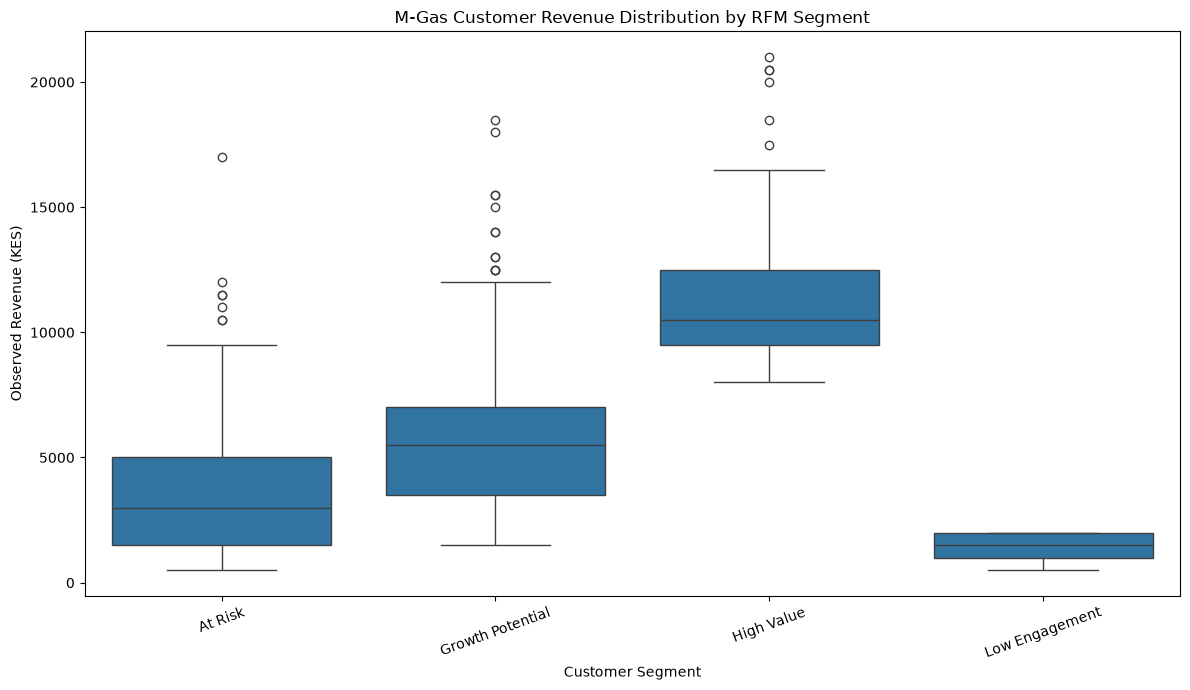

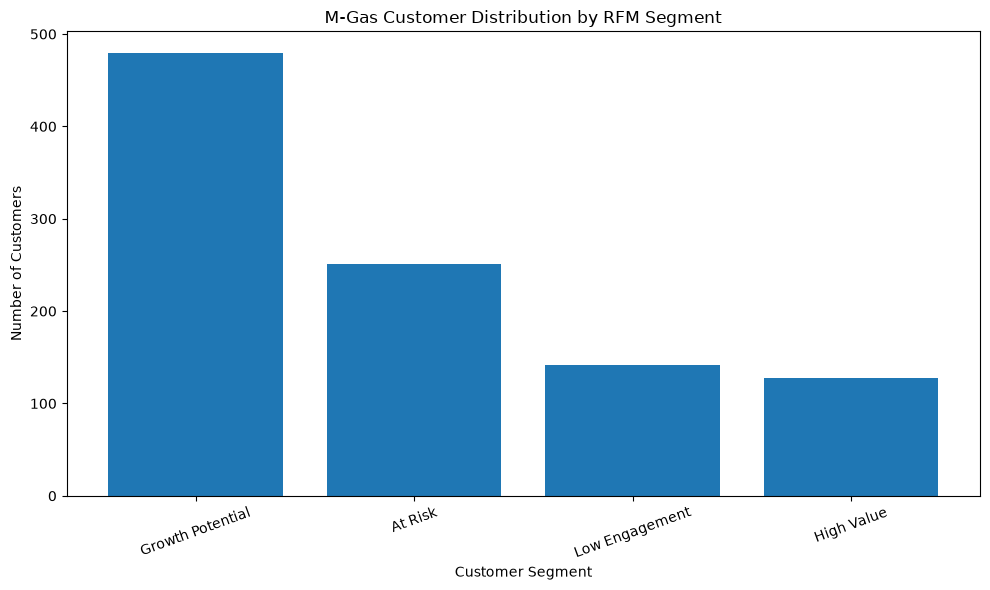


CUSTOMER VALUE INSIGHTS
High-value customers: 128
At-risk customers: 251
Revenue associated with at-risk customers: KES 887,000.00
Low-engagement customers: 142

RECOMMENDED COMMERCIAL ACTIONS

1. HIGH VALUE:
   Introduce loyalty rewards and priority customer support.

2. AT RISK:
   Investigate inactivity and test targeted refill reminders.

3. LOW ENGAGEMENT:
   Investigate affordability, onboarding and purchase frequency.

4. GROWTH POTENTIAL:
   Test campaigns designed to increase repeat-purchase frequency.

5. NOT ACTIVATED:
   Investigate barriers preventing the first successful purchase.


IMPORTANT MODEL LIMITATION
Revenue represents observed successful transaction revenue up to 6 August 2026.
This is historical customer value analysis, not a forecast of future Customer Lifetime Value.
RFM segments are exploratory classifications based on the generated dataset's own distributions.


In [5]:
# ============================================================
# STEP 5: CUSTOMER VALUE & RFM SEGMENTATION
# M-Gas | Scenario anchor: 2026-08-06
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sqlite3

from pathlib import Path


# ============================================================
# 1. LOAD DATA
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Data\commercial-data-analyst-job-m-gas"
)

DB_NAME = PROJECT_ROOT / "data" / "mgas_warehouse.db"

SCENARIO_DATE = pd.Timestamp("2026-08-06 23:59:59")


with sqlite3.connect(str(DB_NAME)) as conn:

    customers = pd.read_sql_query(
        """
        SELECT
            customer_id,
            signup_date,
            segment,
            location,
            agent_id
        FROM Dim_Customer
        """,
        conn
    )

    transactions = pd.read_sql_query(
        """
        SELECT
            transaction_id,
            customer_id,
            transaction_date,
            amount_kes,
            status
        FROM Fact_Transactions
        """,
        conn
    )


# ============================================================
# 2. FILTER SUCCESSFUL TRANSACTIONS
# ============================================================

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

successful = transactions.loc[

    transactions["status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("success")

    & transactions["transaction_date"].notna()

    & transactions["transaction_date"].le(SCENARIO_DATE)

].copy()


# ============================================================
# 3. CALCULATE CUSTOMER VALUE METRICS
# ============================================================

customer_metrics = (

    successful.groupby("customer_id")

    .agg(

        total_revenue_kes=(
            "amount_kes",
            "sum"
        ),

        transaction_frequency=(
            "transaction_id",
            "nunique"
        ),

        last_transaction=(
            "transaction_date",
            "max"
        ),

        average_transaction_value=(
            "amount_kes",
            "mean"
        )

    )

    .reset_index()

)


# Include every customer, even those with zero
# successful transactions.

rfm = customers.merge(

    customer_metrics,

    on="customer_id",

    how="left",

    validate="one_to_one"

)


# Fill customers with no successful transactions.

rfm["total_revenue_kes"] = (
    rfm["total_revenue_kes"].fillna(0)
)

rfm["transaction_frequency"] = (
    rfm["transaction_frequency"].fillna(0)
)


# ============================================================
# 4. CALCULATE RECENCY (FIXED FOR NA HANDLING)
# ============================================================

# For customers with transactions: days since last transaction
# For customers with NO transactions: assign a very high recency
# (they are effectively "lost" — treat as max inactivity)

rfm["recency_days"] = (
    SCENARIO_DATE - rfm["last_transaction"]
).dt.days

# Customers with no successful transaction get max recency
# (they are the most inactive possible)
max_recency = rfm["recency_days"].max()
rfm["recency_days"] = rfm["recency_days"].fillna(max_recency)

# ============================================================
# 5. CALCULATE RFM PERCENTILE SCORES
# ============================================================

# Higher frequency = better score.
# Higher monetary value = better score.
# Lower recency days = better score.

rfm["frequency_score"] = (

    rfm["transaction_frequency"]

    .rank(pct=True)

)

rfm["monetary_score"] = (

    rfm["total_revenue_kes"]

    .rank(pct=True)

)

rfm["recency_score"] = (

    rfm["recency_days"]

    .rank(pct=True, ascending=False)

)


# ============================================================
# 6. DEFINE DATA-DRIVEN SEGMENT THRESHOLDS
# ============================================================

frequency_low = (
    rfm["transaction_frequency"].quantile(0.25)
)

frequency_high = (
    rfm["transaction_frequency"].quantile(0.75)
)

monetary_low = (
    rfm["total_revenue_kes"].quantile(0.25)
)

monetary_high = (
    rfm["total_revenue_kes"].quantile(0.75)
)

recency_high = (
    rfm["recency_days"].quantile(0.75)
)


# ============================================================
# 7. ASSIGN CUSTOMER SEGMENTS
# ============================================================

conditions = [

    # No successful transactions.

    rfm["transaction_frequency"].eq(0),

    # High revenue, frequent purchases,
    # and reasonably recent activity.

    (
        (rfm["monetary_score"] >= 0.75)
        &
        (rfm["frequency_score"] >= 0.75)
        &
        (rfm["recency_score"] >= 0.50)
    ),

    # Previously active customers with
    # unusually long inactivity.

    (
        rfm["recency_days"].ge(recency_high)
        &
        rfm["transaction_frequency"].gt(0)
    ),

    # Customers with low frequency
    # and low historical revenue.

    (
        rfm["transaction_frequency"].le(frequency_low)
        &
        rfm["total_revenue_kes"].le(monetary_low)
    )

]


choices = [

    "Not Activated",

    "High Value",

    "At Risk",

    "Low Engagement"

]


rfm["customer_segment"] = np.select(

    conditions,

    choices,

    default="Growth Potential"

)


# ============================================================
# 8. CUSTOMER SEGMENT SUMMARY
# ============================================================

segment_summary = (

    rfm.groupby("customer_segment")

    .agg(

        customers=(
            "customer_id",
            "nunique"
        ),

        total_revenue_kes=(
            "total_revenue_kes",
            "sum"
        ),

        average_revenue_kes=(
            "total_revenue_kes",
            "mean"
        ),

        average_frequency=(
            "transaction_frequency",
            "mean"
        ),

        average_recency_days=(
            "recency_days",
            "mean"
        )

    )

    .reset_index()

)


segment_summary["customer_share_pct"] = (

    segment_summary["customers"]

    / len(rfm)

    * 100

)

segment_summary["revenue_share_pct"] = (

    segment_summary["total_revenue_kes"]

    / segment_summary["total_revenue_kes"].sum()

    * 100

)


print("\nM-GAS CUSTOMER RFM SEGMENTATION")
print("=" * 75)

print(
    segment_summary.round(2).to_string(index=False)
)


# ============================================================
# 9. VISUALIZE OBSERVED REVENUE BY SEGMENT
# ============================================================

plt.figure(figsize=(12, 7))

sns.boxplot(

    data=rfm,

    x="customer_segment",

    y="total_revenue_kes"

)

plt.title(
    "M-Gas Customer Revenue Distribution by RFM Segment"
)

plt.xlabel("Customer Segment")

plt.ylabel("Observed Revenue (KES)")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()


# ============================================================
# 10. VISUALIZE CUSTOMER DISTRIBUTION
# ============================================================

segment_counts = (

    rfm["customer_segment"]

    .value_counts()

)

plt.figure(figsize=(10, 6))

plt.bar(

    segment_counts.index,

    segment_counts.values

)

plt.title(
    "M-Gas Customer Distribution by RFM Segment"
)

plt.xlabel("Customer Segment")

plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()


# ============================================================
# 11. COMMERCIAL BUSINESS INSIGHTS
# ============================================================

print("\nCUSTOMER VALUE INSIGHTS")
print("=" * 50)

high_value = segment_summary.loc[
    segment_summary["customer_segment"] == "High Value"
]

at_risk = segment_summary.loc[
    segment_summary["customer_segment"] == "At Risk"
]

low_engagement = segment_summary.loc[
    segment_summary["customer_segment"] == "Low Engagement"
]


if not high_value.empty:

    print(
        f"High-value customers: "
        f"{int(high_value['customers'].iloc[0])}"
    )

if not at_risk.empty:

    print(
        f"At-risk customers: "
        f"{int(at_risk['customers'].iloc[0])}"
    )

    print(
        f"Revenue associated with at-risk customers: "
        f"KES {at_risk['total_revenue_kes'].iloc[0]:,.2f}"
    )

if not low_engagement.empty:

    print(
        f"Low-engagement customers: "
        f"{int(low_engagement['customers'].iloc[0])}"
    )


print("\nRECOMMENDED COMMERCIAL ACTIONS")

print(
    """
1. HIGH VALUE:
   Introduce loyalty rewards and priority customer support.

2. AT RISK:
   Investigate inactivity and test targeted refill reminders.

3. LOW ENGAGEMENT:
   Investigate affordability, onboarding and purchase frequency.

4. GROWTH POTENTIAL:
   Test campaigns designed to increase repeat-purchase frequency.

5. NOT ACTIVATED:
   Investigate barriers preventing the first successful purchase.
"""
)


print("\nIMPORTANT MODEL LIMITATION")

print(
    "Revenue represents observed successful transaction "
    "revenue up to 6 August 2026."
)

print(
    "This is historical customer value analysis, "
    "not a forecast of future Customer Lifetime Value."
)

print(
    "RFM segments are exploratory classifications "
    "based on the generated dataset's own distributions."
)